In [46]:
# Chargement des bibliothèques de base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Description des variables

Le jeu de données contient **1 000 trajets de taxi** décrits par **11 variables** : 10 variables explicatives et 1 variable cible (`Trip_Price`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Trip_Distance_km` | Numérique (continue) | Distance parcourue pendant le trajet, en kilomètres | 1,23 – 146,07 km (médiane ≈ 25,8) |
| `Time_of_Day` | Catégorielle | Moment de la journée où le trajet a lieu | `Morning`, `Afternoon`, `Evening`, `Night` |
| `Day_of_Week` | Catégorielle | Type de jour du trajet | `Weekday` (semaine), `Weekend` (week-end) |
| `Passenger_Count` | Numérique (discrète) | Nombre de passagers à bord | 1 – 4 |
| `Traffic_Conditions` | Catégorielle (ordinale) | Niveau de congestion du trafic | `Low`, `Medium`, `High` |
| `Weather` | Catégorielle | Conditions météorologiques pendant le trajet | `Clear` (dégagé), `Rain` (pluie), `Snow` (neige) |
| `Base_Fare` | Numérique (continue) | Tarif de prise en charge, fixe au démarrage de la course | 2,01 – 5,00 |
| `Per_Km_Rate` | Numérique (continue) | Tarif appliqué par kilomètre parcouru | 0,50 – 2,00 |
| `Per_Minute_Rate` | Numérique (continue) | Tarif appliqué par minute de trajet | 0,10 – 0,50 |
| `Trip_Duration_Minutes` | Numérique (continue) | Durée totale du trajet, en minutes | 5,01 – 119,84 min (médiane ≈ 61,9) |
| **`Trip_Price`** | Numérique (continue) | **Variable cible** : prix total payé pour la course | 6,13 – 332,04 (médiane ≈ 50,1) |


In [47]:
# Lecture du fichier de données
jeu_donnees = pd.read_csv("taxi_trip_pricing.csv")
jeu_donnees.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [48]:
# Nombre de lignes et de colonnes
jeu_donnees.shape

(1000, 11)

In [49]:
# Résumé des colonnes et de leurs types
jeu_donnees.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    str    
 2   Day_of_Week            950 non-null    str    
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    str    
 5   Weather                950 non-null    str    
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), str(4)
memory usage: 108.5 KB


### <font color = 'bisque'>Exploration et préparation des données

In [50]:
# Isoler les colonnes numériques
donnees_numeriques = jeu_donnees.select_dtypes(include = "number")
donnees_numeriques.head()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,3.0,3.56,0.80,0.32,53.82,36.2624
1,47.59,1.0,NaN,0.62,0.43,40.57,NaN
2,36.87,1.0,2.70,1.21,0.15,37.27,52.9032
3,30.33,4.0,3.48,0.51,0.15,116.81,36.4698
4,NaN,3.0,2.93,0.63,0.32,22.64,15.6180


In [51]:
# Statistiques descriptives des colonnes numériques
donnees_numeriques.describe()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,951.000000
mean,27.070547,2.476842,3.502989,1.233316,0.292916,62.118116,56.874773
std,19.905300,1.102249,0.870162,0.429816,0.115592,32.154406,40.469791
min,1.230000,1.000000,2.010000,0.500000,0.100000,5.010000,6.126900
25%,12.632500,1.250000,2.730000,0.860000,0.190000,35.882500,33.742650
50%,25.830000,2.000000,3.520000,1.220000,0.290000,61.860000,50.074500
75%,38.405000,3.000000,4.260000,1.610000,0.390000,89.055000,69.099350
max,146.067047,4.000000,5.000000,2.000000,0.500000,119.840000,332.043689


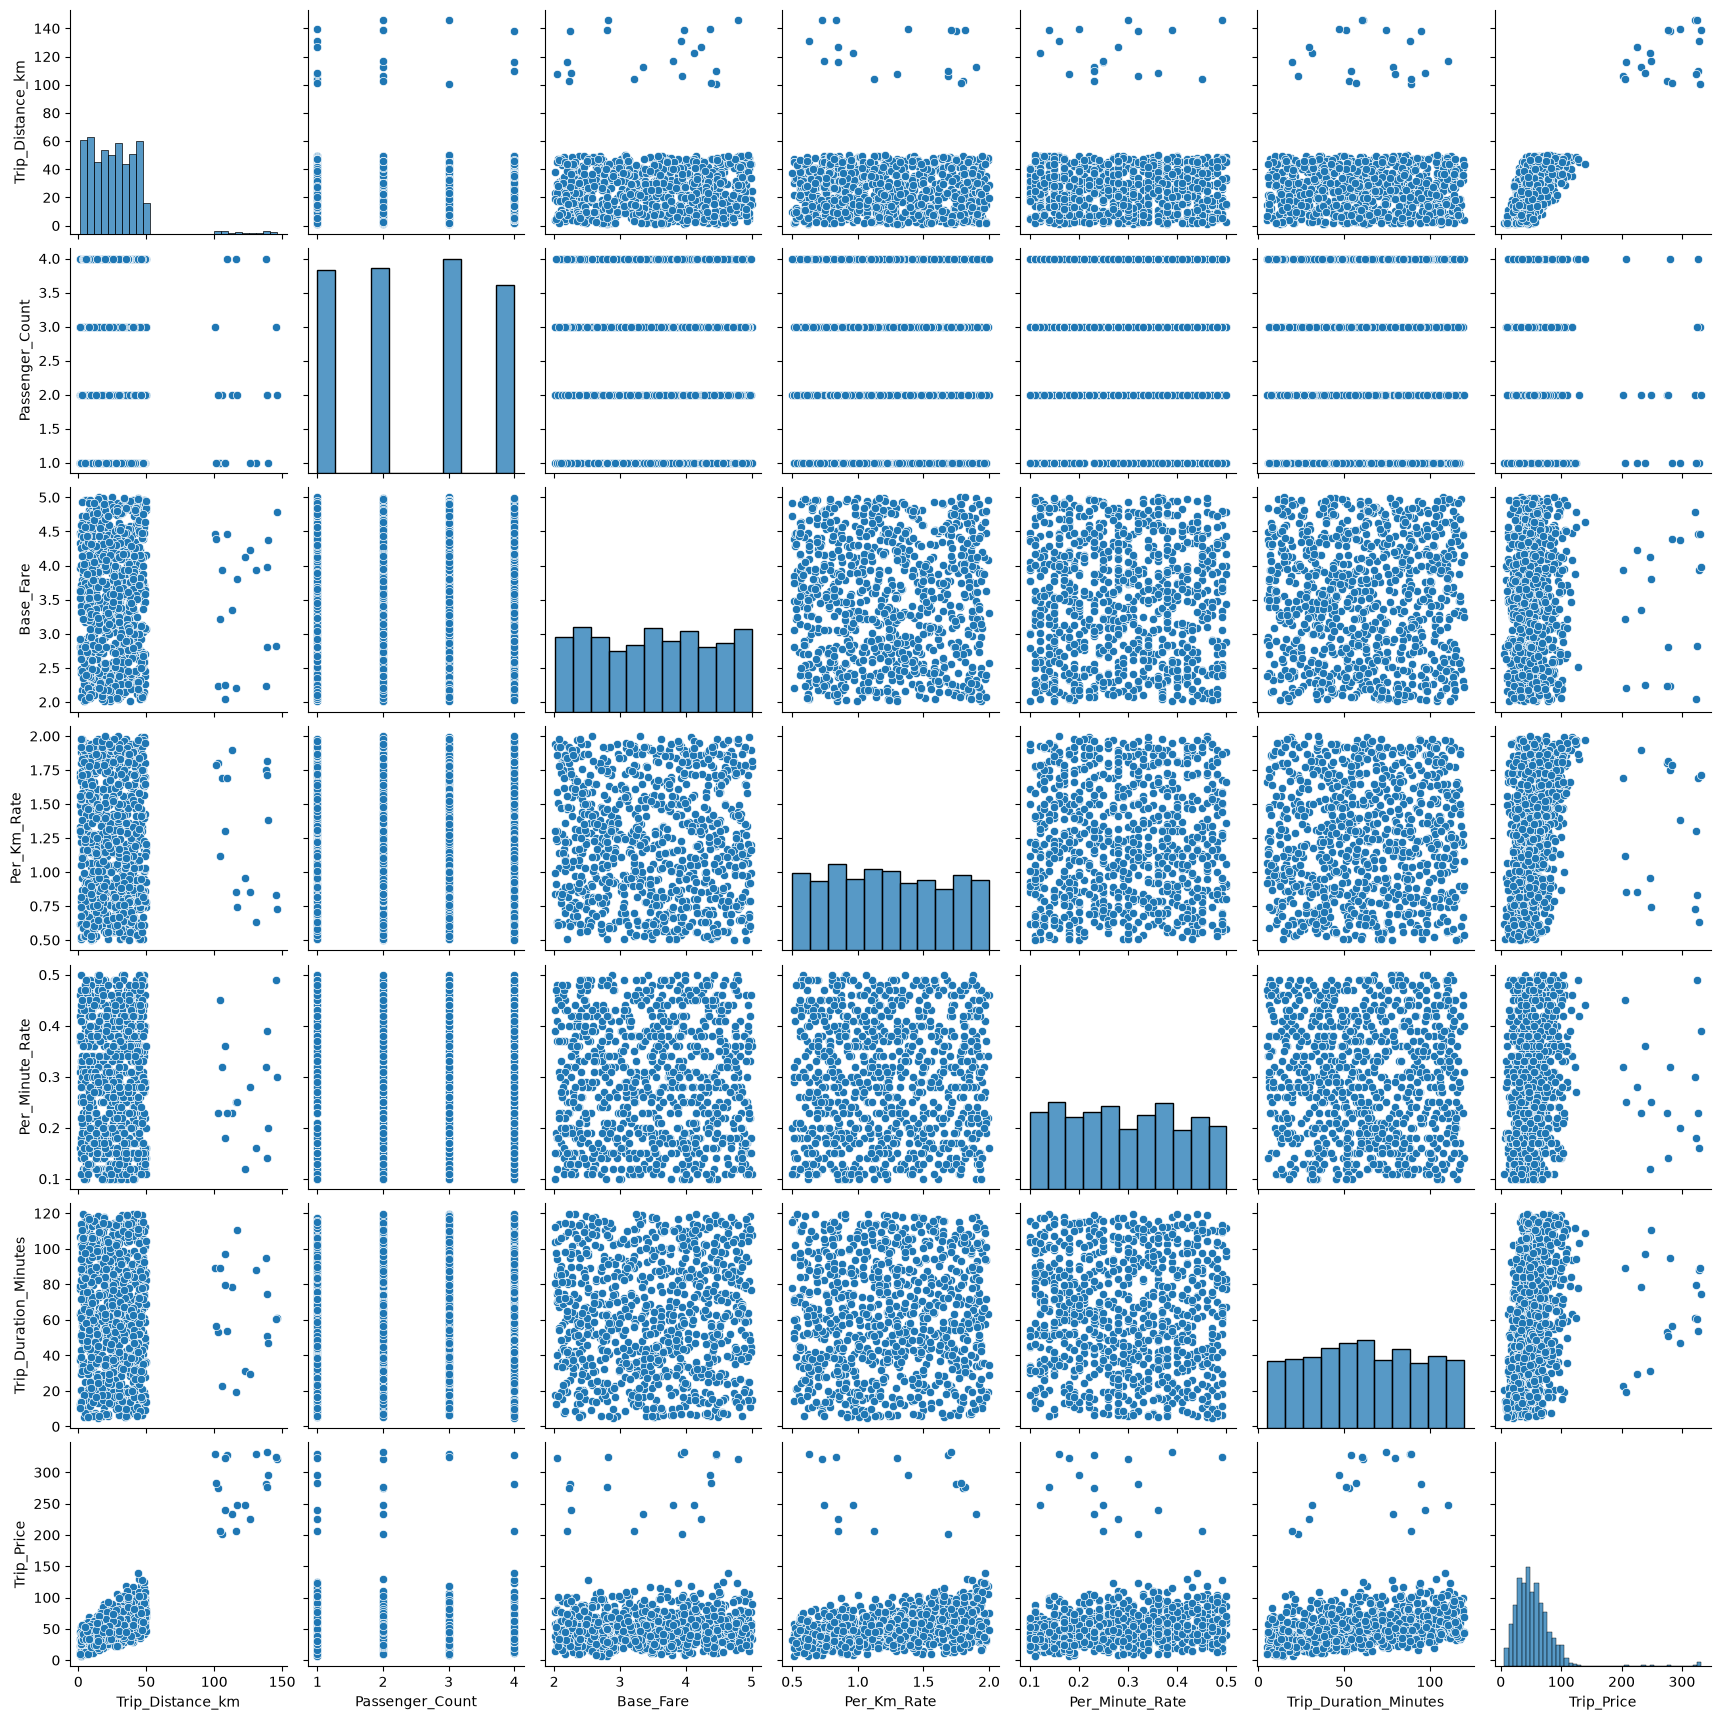

In [52]:
# Nuages de points croisés des colonnes numériques
sns.pairplot(donnees_numeriques)
plt.show()

In [53]:
# Fonction qui trace la boîte à moustaches d'une colonne
def tracer_boite_moustaches(colonne):
    graphique = px.box(jeu_donnees,x = colonne)
    graphique.show()

In [54]:
# Appliquer la fonction tracer_boite_moustaches à chaque colonne
for colonne in donnees_numeriques.columns:
  tracer_boite_moustaches(colonne)

<Axes: >

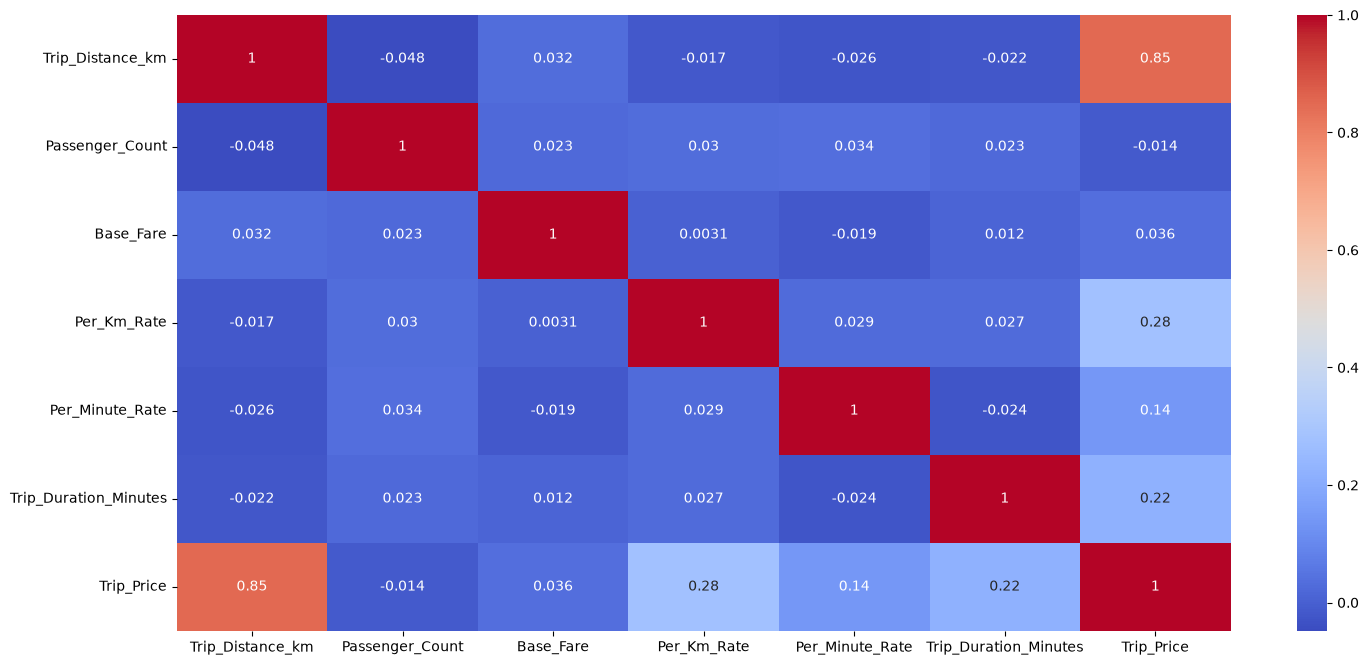

In [55]:
# Matrice de corrélation sous forme de carte de chaleur
plt.figure(figsize=(17,8))
sns.heatmap(donnees_numeriques.corr(), annot=True, cmap= "coolwarm")

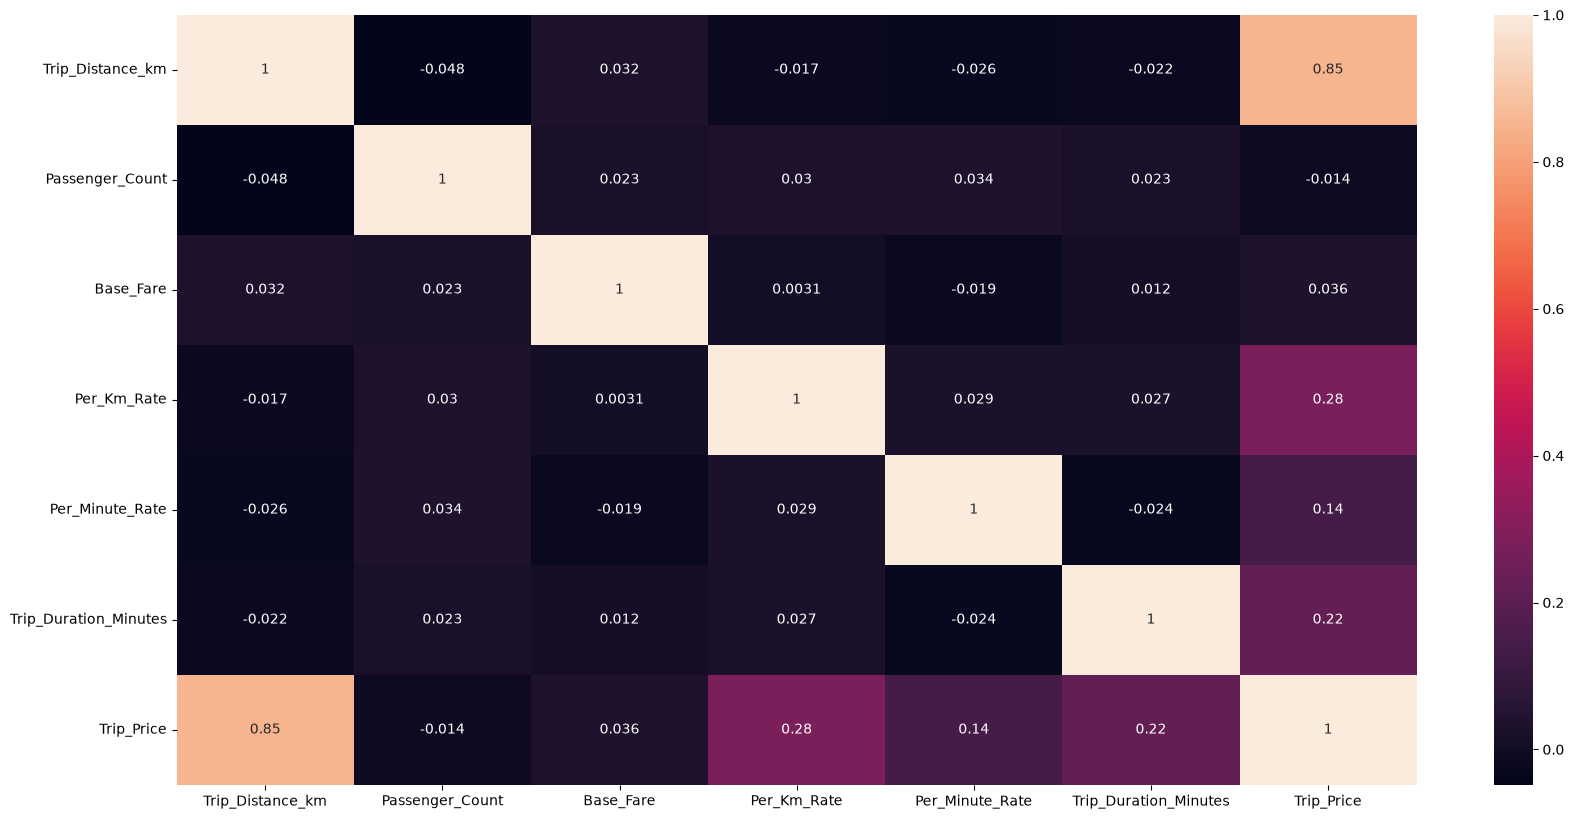

In [56]:
# Matrice de corrélation, en plus grand
plt.figure(figsize = (20, 10))
sns.heatmap(donnees_numeriques.corr(), annot = True)
plt.show()

In [57]:
# Isoler les colonnes catégorielles
donnees_categorielles = jeu_donnees.select_dtypes(exclude = "number")

In [58]:
# Statistiques descriptives des colonnes catégorielles
donnees_categorielles.describe()

,Time_of_Day,Day_of_Week,Traffic_Conditions,Weather
count,950,950,950,950
unique,4,2,3,3
top,Afternoon,Weekday,Low,Clear
freq,371,655,397,667


In [59]:
# Fonction qui trace le diagramme en barres des effectifs d'une colonne
def tracer_diagramme_barres(colonne):
    effectifs = donnees_categorielles[colonne].value_counts()
    graphique = px.bar(x = effectifs.index, y = effectifs.values,color = effectifs.index.astype(str), text_auto = True)
    graphique.show()

In [60]:
# Appliquer la fonction tracer_diagramme_barres à chaque colonne
for colonne in donnees_categorielles:
    tracer_diagramme_barres(colonne)

In [61]:
# Remplacer les valeurs manquantes des colonnes catégorielles par le mode
for colonne in donnees_categorielles.columns:
  jeu_donnees.fillna({colonne: jeu_donnees[colonne].mode()[0]}, inplace = True)

In [62]:
import joblib as jb
# Mémoriser les valeurs uniques de chaque variable catégorielle (dictionnaire {colonne: valeurs})
# (format lu par l'application Streamlit, app.py)
valeurs_uniques_par_colonne = {colonne: np.unique(jeu_donnees[colonne]).tolist() for colonne in donnees_categorielles.columns}
# Enregistrement dans le dossier models/ de l'application
jb.dump(valeurs_uniques_par_colonne, "./models/taxi_uniques_dict.joblib")
valeurs_uniques_par_colonne['Time_of_Day']

['Afternoon', 'Evening', 'Morning', 'Night']

In [63]:
# Encodage des variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Un encodeur par variable catégorielle, rangé dans un dictionnaire {colonne: encodeur}
# (format lu par l'application Streamlit, app.py)
encodeurs_par_colonne = {}
for colonne in donnees_categorielles.columns:
  encodeur_colonne = LabelEncoder()
  encodeur_colonne.fit(jeu_donnees[colonne]) # Apprentissage des classes de la colonne
  jeu_donnees[colonne] = encodeur_colonne.transform(jeu_donnees[colonne]) # Transformation des valeurs en codes
  encodeurs_par_colonne[colonne] = encodeur_colonne

# Classes de chaque variable, dans l'ordre de leurs codes
{colonne: encodeurs_par_colonne[colonne].classes_.tolist() for colonne in donnees_categorielles.columns}

{'Time_of_Day': ['Afternoon', 'Evening', 'Morning', 'Night'],
 'Day_of_Week': ['Weekday', 'Weekend'],
 'Traffic_Conditions': ['High', 'Low', 'Medium'],
 'Weather': ['Clear', 'Rain', 'Snow']}

In [64]:
# Enregistrement des encodeurs dans le dossier models/
jb.dump(encodeurs_par_colonne, "./models/taxi_encoders_v2.joblib")

['./models/taxi_encoders_v2.joblib']

In [65]:
from sklearn.impute import KNNImputer
# Remplacer les valeurs manquantes des colonnes numériques (KNN)
imputateur_knn = KNNImputer(n_neighbors=5)
jeu_donnees[:] = imputateur_knn.fit_transform(jeu_donnees)

In [66]:
# Fonction de remplacement des valeurs aberrantes par imputation
def traiter_valeurs_aberrantes(jeu_donnees, colonne, n_neighbors=5):
    # Détection des valeurs aberrantes (méthode de l'écart interquartile)
    quartile_1 = jeu_donnees[colonne].quantile(0.25)
    quartile_3 = jeu_donnees[colonne].quantile(0.75)
    ecart_interquartile = quartile_3 - quartile_1
    borne_inferieure = quartile_1 - 1.5 * ecart_interquartile
    borne_superieure = quartile_3 + 1.5 * ecart_interquartile

    # Les valeurs hors bornes passent à NaN pour que le KNNImputer les remplace
    jeu_donnees.loc[(jeu_donnees[colonne] < borne_inferieure) | (jeu_donnees[colonne] > borne_superieure), colonne] = np.nan # marquer comme valeur manquante
    # n_neighbors : nombre de voisins utilisés pour calculer la valeur de remplacement
    imputateur_knn = KNNImputer(n_neighbors=n_neighbors)
    jeu_donnees[:] = imputateur_knn.fit_transform(jeu_donnees)

In [67]:
# Traitement des valeurs aberrantes, colonne par colonne
for colonne in donnees_numeriques :
    traiter_valeurs_aberrantes(jeu_donnees,colonne)

In [68]:
# Retracer les boîtes à moustaches après traitement
for colonne in donnees_numeriques:
    tracer_boite_moustaches(colonne)

In [69]:
# Séparer explicatives et cible
# Ordre des variables explicatives (à respecter au moment des prédictions)
noms_variables_explicatives = jeu_donnees.columns[:-1].tolist()
jb.dump(noms_variables_explicatives, "./models/taxi_features.joblib")
caracteristiques = jeu_donnees.iloc[:,:-1].values
cible = jeu_donnees.iloc[:, -1].values
noms_variables_explicatives

['Trip_Distance_km',
 'Time_of_Day',
 'Day_of_Week',
 'Passenger_Count',
 'Traffic_Conditions',
 'Weather',
 'Base_Fare',
 'Per_Km_Rate',
 'Per_Minute_Rate',
 'Trip_Duration_Minutes']

In [70]:
# Import du RobustScaler
from sklearn.preprocessing import RobustScaler
# Mise à l'échelle des variables explicatives
mise_a_echelle = RobustScaler()
mise_a_echelle.fit(caracteristiques)
caracteristiques = mise_a_echelle.transform(caracteristiques)

In [71]:
# Enregistrement du normaliseur dans le dossier models/
jb.dump(mise_a_echelle, "./models/taxi_scaler.joblib")

['./models/taxi_scaler.joblib']

In [72]:
from sklearn.model_selection import train_test_split
# Première coupe : entraînement (80 %) et reste (20 %)
x_entrainement, x_validation_test,y_entrainement,y_validation_test = train_test_split(caracteristiques,cible , test_size = 0.2, random_state = 42)
# Seconde coupe : le reste est partagé en validation et test
x_validation, x_test, y_validation, y_test = train_test_split(x_validation_test, y_validation_test, test_size = 0.5, random_state = 42)

In [73]:
# Vérification visuelle
x_entrainement[:5]

array([[-0.88108926,  0.        ,  0.        , -0.4       ,  1.        ,
         0.        , -0.44367418,  0.75555556, -0.45      ,  0.31155828],
       [ 0.89440242,  0.5       ,  1.        , -1.4       , -1.        ,
         0.        , -0.56152513,  0.74166667, -0.75      ,  0.50034024],
       [ 0.23398891,  0.5       ,  0.        ,  1.6       ,  0.        ,
         1.        , -0.72790295,  0.13055556, -0.3       , -0.89987363],
       [-0.91618759, -0.5       ,  0.        , -0.4       ,  0.        ,
         0.        , -0.03466205, -0.48055556, -0.5       , -0.59793915],
       [ 0.83550177,  0.5       ,  1.        ,  0.6       ,  1.        ,
         0.        , -0.70710572, -0.89722222,  0.95      , -0.3755225 ]])

### <font color = 'bisque'>Multiple Linear Regression

In [74]:
# Recherche des meilleurs paramètres de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée à 5 plis, mélange figé par la graine
validation_croisee = KFold(n_splits=5, shuffle=True, random_state=42)
# Grille des paramètres à tester
grille_reg_lineaire = {
    'fit_intercept': [True, False],
    'positive': [True, False]
 }
# Création du modèle
reg_lineaire = LinearRegression()
# Création de la recherche sur grille
recherche_reg_lineaire = GridSearchCV(reg_lineaire, grille_reg_lineaire, cv = validation_croisee)
# Lancer la recherche
recherche_reg_lineaire.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [75]:
# Récupérer le meilleur modèle trouvé par la recherche
modele_reg_lineaire = recherche_reg_lineaire.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [76]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calcul du R2, de la MSE, de la MAE et de la RMSE
# from math import *
def evaluer_modele(modele):
  y_predit = modele.predict(x_validation)
  score_r2 = r2_score(y_validation, y_predit)
  erreur_quad = mean_squared_error(y_validation, y_predit)
  erreur_abs = mean_absolute_error(y_validation, y_predit)
  racine_erreur_quad = root_mean_squared_error(y_validation, y_predit)
  return score_r2, erreur_quad, erreur_abs, racine_erreur_quad

In [77]:
# Évaluation sur la validation
r2_reg_lineaire, mse_reg_lineaire, mae_reg_lineaire, rmse_reg_lineaire = evaluer_modele(modele_reg_lineaire)
print(f"R2: {r2_reg_lineaire}, mse: {mse_reg_lineaire}, mae: {mae_reg_lineaire}, rmse: {rmse_reg_lineaire}")

R2: 0.864514089167485, mse: 71.6188851446698, mae: 6.725709389585957, rmse: 8.462794168870575


### <font color = 'bisque'>Ridge Regression

In [78]:
# Recherche des meilleurs paramètres de l'algorithme
from sklearn.linear_model import Ridge
# Grille des paramètres à tester
grille_ridge = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) # plage de 10^-8 à 10^8, en 100 valeurs
 }
# Création du modèle
reg_ridge = Ridge()
# Création de la recherche sur grille
recherche_ridge = GridSearchCV(reg_ridge, grille_ridge, cv = validation_croisee)
# Lancer la recherche
recherche_ridge.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.0000...00000000e+08]), 'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int,

In [79]:
# Récupérer le meilleur modèle trouvé par la recherche
modele_ridge = recherche_ridge.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [80]:
# Évaluation du modèle
r2_ridge, mse_ridge, mae_ridge, rmse_ridge = evaluer_modele(modele_reg_lineaire)
print(f"R2: {r2_ridge}, mse: {mse_ridge}, mae: {mae_ridge}, rmse: {rmse_ridge}")

R2: 0.864514089167485, mse: 71.6188851446698, mae: 6.725709389585957, rmse: 8.462794168870575


### <font color = 'bisque'>Decision Tree Regressor<font>

In [81]:
# Recherche des meilleurs paramètres de l'arbre de décision
from sklearn.tree import DecisionTreeRegressor
# Grille des paramètres à tester
grille_arbre = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Création du modèle
arbre = DecisionTreeRegressor(random_state = 42)
# Création de la recherche sur grille
recherche_arbre = GridSearchCV(arbre, grille_arbre, cv = validation_croisee)
# Lancer la recherche
recherche_arbre.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': array([ 1, 2..., 27, 28, 29])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verb

In [82]:
# Récupérer le meilleur modèle trouvé par la recherche
modele_arbre = recherche_arbre.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [83]:
# Évaluation du modèle
r2_arbre, mse_arbre, mae_arbre, rmse_arbre = evaluer_modele(modele_arbre)
print(f"R2: {r2_arbre}, mse: {mse_arbre}, mae: {mae_arbre}, rmse: {rmse_arbre}")

R2: 0.7921831661197744, mse: 109.85356237664904, mae: 8.01475512, rmse: 10.481105016965007


### <font color = 'bisque'>Random Forest Regressor<font>

In [84]:
from sklearn.ensemble import RandomForestRegressor

# Grille des paramètres à tester
grille_foret = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Création du modèle
foret =  RandomForestRegressor()
# Création de la recherche sur grille
recherche_foret = GridSearchCV(foret, grille_foret, cv=validation_croisee)
# Lancer la recherche
recherche_foret.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [85]:
# Récupérer le meilleur modèle trouvé par la recherche
modele_foret = recherche_foret.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [86]:
# Évaluation du modèle
r2_foret, mse_foret, mae_foret, rmse_foret = evaluer_modele(modele_foret)
print(f"R2: {r2_foret}, mse: {mse_foret}, mae: {mae_foret}, rmse: {rmse_foret}")

R2: 0.8977318979825717, mse: 54.0596982176527, mae: 5.313891676127713, rmse: 7.35253005554229


In [87]:
# Comparaison des métriques de tous les modèles
noms_modeles = ["LR", "RR", "DT", "RF"]
liste_r2 = [r2_reg_lineaire, r2_ridge, r2_arbre, r2_foret]
liste_mse = [mse_reg_lineaire, mse_ridge, mse_arbre, mse_foret]
liste_rmse= [rmse_reg_lineaire, rmse_ridge, rmse_arbre, rmse_foret]
liste_mae = [mae_reg_lineaire, mae_ridge, mae_arbre, mae_foret]
liste_resultats = [liste_r2, liste_mse, liste_rmse, liste_mae]

for indice in range(4):
    graphique = px.bar(y = noms_modeles, x = liste_resultats[indice], color = noms_modeles, text_auto = True)
    graphique.show()

In [88]:
# Enregistrement du meilleur modèle dans le dossier models/
jb.dump(modele_foret, "./models/taxi_model.joblib")

['./models/taxi_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [89]:
# Extrait des 10 premiers exemples de test
x_test_extrait = x_test[:10]
y_test_extrait = y_test[:10]
# Prédictions sur cet extrait
y_pred_extrait = modele_foret.predict(x_test_extrait)
# Afficher prédiction et valeur réelle, une ligne par exemple
for indice in range(10):
  print(f"Prédiction {indice + 1} : {y_pred_extrait[indice]:.2f}$ --Réel :{y_test_extrait[indice]:.2f}$")

Prédiction 1 : 12.96$ --Réel :13.06$
Prédiction 2 : 14.35$ --Réel :12.73$
Prédiction 3 : 76.97$ --Réel :86.90$
Prédiction 4 : 27.24$ --Réel :29.86$
Prédiction 5 : 51.78$ --Réel :57.08$
Prédiction 6 : 48.52$ --Réel :46.81$
Prédiction 7 : 41.38$ --Réel :40.36$
Prédiction 8 : 72.97$ --Réel :81.85$
Prédiction 9 : 30.43$ --Réel :27.16$
Prédiction 10 : 49.80$ --Réel :54.44$


### <font color = 'teal'>Déploiement<font>

Le déploiement est réalisé avec **Streamlit** dans `app.py` (page 🚕 Taxi).
Fichiers produits dans `models/` :
`taxi_model.joblib`, `taxi_encoders_v2.joblib`, `taxi_scaler.joblib`, `taxi_uniques_dict.joblib`, `taxi_features.joblib`.

In [90]:
# (ancien déploiement Gradio, remplacé par Streamlit : voir app.py)